# **SUPPLY CHAIN ANALYSIS**

## **Business Problem**

>A global e-commerce company is operating across multiple regions manages end-to-end order fulfilment, including shipping and delivery, for products like sporting goods. The company is facing incinsistent delivery performance, where actual shipping times often deviate from scheduled timelines, leading to late deliveries and unpredictable order profitability.

### Desired Outcome:
>The goal is to analyze delivery operations, identify bottlenecks, and build a predictive system to reduce delays, optimize shipping decisions, and improve aoverall profitability and efficiency.

In [1]:
# Importing necessary packages

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm

In [2]:
# Loading the data and examining the first 10 rows

df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding = "latin-1")
pd.set_option("display.max_columns",None)

In [3]:
df.head(10)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class
5,TRANSFER,6,4,18.580000,294.980011,Shipping canceled,0,73,Sporting Goods,Tonawanda,EE. UU.,XXXXXXXXX,Kimberly,19488,Flowers,XXXXXXXXX,Consumer,NY,2122 Hazy Corner,14150.0,2,Fitness,43.013969,-78.879066,Pacific Asia,Toowoomba,Australia,19488,1/13/2018 11:03,75935,1360,32.779999,0.10,179250,327.75,0.06,1,327.75,294.980011,18.580000,Oceania,Queensland,CANCELED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/19/2018 11:03,Standard Class
6,DEBIT,2,1,95.180000,288.420013,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Constance,19487,Terrell,XXXXXXXXX,Home Office,PR,1879 Green Pine Bank,725.0,2,Fitness,18.242538,-66.037056,Pacific Asia,Guangzhou,China,19487,1/13/2018 10:42,75934,1360,39.330002,0.12,179249,327.75,

## **Exploratory Data Analysis (EDA)**

In [4]:
# Checking the number of rows and columns in the dataset
df.shape

(180519, 53)

In [5]:
# Checking what columns are part of the dataset

df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [6]:
# Checking for duplicates
df.duplicated().sum()

np.int64(0)

In [7]:
df.isna().sum().sort_values(ascending=False)

Product Description              180519
Order Zipcode                    155679
Customer Lname                        8
Customer Zipcode                      3
Days for shipment (scheduled)         0
Sales per customer                    0
Benefit per order                     0
Delivery Status                       0
Late_delivery_risk                    0
Customer City                         0
Customer Country                      0
Category Id                           0
Category Name                         0
Customer Fname                        0
Customer Email                        0
Customer Password                     0
Customer Id                           0
Customer Segment                      0
Customer State                        0
Days for shipping (real)              0
Type                                  0
Department Id                         0
Customer Street                       0
Department Name                       0
Latitude                              0


In [8]:
df.columns.to_list()

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Email',
 'Customer Fname',
 'Customer Id',
 'Customer Lname',
 'Customer Password',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Customer Zipcode',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country',
 'Order Customer Id',
 'order date (DateOrders)',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Image',
 'Product Name',
 'Product P

In [9]:
# Both columns contain the same information

(df["Benefit per order"] == df["Order Profit Per Order"]).value_counts()

True    180519
Name: count, dtype: int64

In [10]:
# This column contains only one single value 

df["Product Status"].value_counts()

Product Status
0    180519
Name: count, dtype: int64

In [11]:
# Creating a list of redundant or unnecessary columns to drop

columns_to_drop = ['Product Description',
                   'Product Image',
                   'Customer Email',
                   'Customer Password',
                   'Customer Fname',
                   'Customer Lname',
                   'Customer Street',
                   'Customer Zipcode',
                   'Order Zipcode',
                   'Longitude',
                   'Latitude',
                   'Order Item Cardprod Id',
                   'Order Item Id',
                   'Order Item Discount',
                   'Order Item Discount Rate',
                   'Order Item Product Price',
                   'Order Item Quantity',
                   'Order Item Total',
                   'Category Id',
                   'Department Id',
                   'Order Id',
                   'Order Customer Id',
                   'Customer Id',
                   'Product Card Id',
                   'Product Category Id',
                   'Benefit per order', # Identical to Order Profit Per Order
                   'Product Status', # Has only one value
                   'Customer City',
                   'Order City',
                   'Order Country',
                   'Order State',
                   'Customer State',
                   'Market']

# Dropping the columns that are either fully missing, redundant or have only one value (and thus no variance)
df = df.drop(columns = columns_to_drop)

In [12]:
# Removing the canceled orders column since it is not relevant for delivery time analysis and may have different patterns that delivered orders
df = df[df["Delivery Status"] != "Shipping canceled"]

# Standard date conversion
for c in ["order date (DateOrders)","shipping date (DateOrders)"]:
    df[c] = pd.to_datetime(df[c], errors="coerce", dayfirst=False)

#Checking the data after cleaning
print(f"---Rows and Columns: {df.shape}")
print(f"\n---Missing values:\n{df.isna().sum().sort_values(ascending=False)}")

---Rows and Columns: (172765, 20)

---Missing values:
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Sales per customer               0
Delivery Status                  0
Late_delivery_risk               0
Category Name                    0
Customer Country                 0
Customer Segment                 0
Department Name                  0
order date (DateOrders)          0
Order Item Profit Ratio          0
Sales                            0
Order Profit Per Order           0
Order Region                     0
Order Status                     0
Product Name                     0
Product Price                    0
shipping date (DateOrders)       0
Shipping Mode                    0
dtype: int64


In [13]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-31 22:56:00,0.29,327.75,91.250000,Southeast Asia,COMPLETE,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-13 12:27:00,-0.80,327.75,-249.089996,South Asia,PENDING,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,2018-01-13 12:06:00,-0.80,327.75,-247.779999,South Asia,CLOSED,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,2018-01-13 11:45:00,0.08,327.75,22.860001,Oceania,COMPLETE,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,2018-01-13 11:24:00,0.45,327.75,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.75,2018-01-15 11:24:00,Standard Class


In [14]:
# Value counts for categorical columns with low cardinality to see what values exist in these columns
for col in df.columns:
    if df[col].nunique() < 10:
        print("_"*50)
        print(f"\n*---{df[col].value_counts()}")

__________________________________________________

*---Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64
__________________________________________________

*---Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64
__________________________________________________

*---Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64
__________________________________________________

*---Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64
__________________________________________________

*---Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64
__________________________________________________

*---Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64
__________________________________________________

*--

In [15]:
df.columns.to_list()

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Name',
 'Customer Country',
 'Customer Segment',
 'Department Name',
 'order date (DateOrders)',
 'Order Item Profit Ratio',
 'Sales',
 'Order Profit Per Order',
 'Order Region',
 'Order Status',
 'Product Name',
 'Product Price',
 'shipping date (DateOrders)',
 'Shipping Mode']

In [16]:
# Calculating irder processing time and delay

df["Order Processing Time"] = (df["shipping date (DateOrders)"] - df["order date (DateOrders)"]).dt.days
df["Delay"] = df["Order Processing Time"] - df["Days for shipment (scheduled)"]
df["Is_Delayed"] = df["Delay"] > 0
df["order_month"] = df["order date (DateOrders)"].dt.month
df["order_day"] = df["order date (DateOrders)"].dt.day_name()
df["order_hour"] = df["order date (DateOrders)"].dt.hour
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,Delay,order_month,order_hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991,0.120801,203.828493,22.032360,141.278595,2016-06-16 03:25:14.452927,3.472816,0.539716,6.235511,11.482604
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,119.980003,7.030000,50.000000,2015-09-25 08:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 03:38:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 08:00:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,132.392520,104.355313,139.862956,NaN,1.670187,1.494150,3.405593,6.927276


In [17]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Sales per customer', 'Delivery Status', 'Late_delivery_risk',
       'Category Name', 'Customer Country', 'Customer Segment',
       'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio',
       'Sales', 'Order Profit Per Order', 'Order Region', 'Order Status',
       'Product Name', 'Product Price', 'shipping date (DateOrders)',
       'Shipping Mode', 'Order Processing Time', 'Delay', 'Is_Delayed',
       'order_month', 'order_day', 'order_hour'],
      dtype='str')

In [18]:
# Profitability Flag based on Order Profit Per Order

df["Profitability Flag"] = np.where(df["Order Profit Per Order"] > 0 ,"Profit", np.where(df["Order Profit Per Order"]< 0, "Loss", "Break-Even"))
df["Profitability Flag"].value_counts()

Profitability Flag
Profit        139354
Loss           32295
Break-Even      1116
Name: count, dtype: int64

In [19]:
df["Profitability Flag"].value_counts(normalize=True)*100

Profitability Flag
Profit        80.661014
Loss          18.693022
Break-Even     0.645964
Name: proportion, dtype: float64

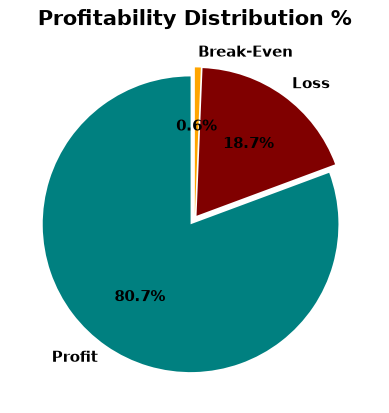

In [20]:
# Visualizing the profitability distribution

df["Profitability Flag"].value_counts().plot(kind="pie",autopct="%1.1f%%", colors = ["teal","maroon","orange"],startangle=90, explode=[0.05,0.02,0.02],textprops={"fontweight":"bold","fontsize":11})
plt.title("Profitability Distribution %", fontweight="bold",fontsize=15)
plt.show()

In [21]:
# Creating a function to make dollar amounts easy to read

def format_func(value):
    if value >= 1e6:
        return(f"{value/1e6:.1f}M $")
    elif value >= 1e3:
        return(f"{value/1e3:.1f}K $")
    else:
        return(f"{value:.0f}$")


delayed_df = df[df["Delay"] > 0]
metrics = {}
metrics["Total Orders"] = len(df)
metrics["Late Deliveries"] = len(delayed_df)
metrics["90% Delay (days)"] = delayed_df["Delay"].quantile(0.90)
metrics["On time Delivery %"] = ( 1 - float(metrics["Late Deliveries"]) / metrics["Total Orders"]) * 100
metrics["Late Delivery %"] = float(metrics["Late Deliveries"]) / metrics["Total Orders"] * 100
metrics["Total Profit"] = format_func(df.loc[df["Order Profit Per Order"] > 0, "Order Profit Per Order"].sum())
metrics["Total Loss due to delays"] = format_func(df.loc[df["Delay"] > 0, "Order Profit Per Order"].sum())

print("\n---Business KPIs---\n")
for k, v in metrics.items():
    if isinstance(v,float):
        print(f"{k}:{v:.2f}")
    else:
        print(f"{k}:{v}")


---Business KPIs---

Total Orders:172765
Late Deliveries:94523
90% Delay (days):3.00
On time Delivery %:45.29
Late Delivery %:54.71
Total Profit:7.5M $
Total Loss due to delays:2.1M $


## **Profitability vs Delivery Time Analysis**

In [22]:
profit_metrics = (df.groupby("Delay")["Order Profit Per Order"].agg(
        mean_profit = "mean", total_profit = "sum", order_count="count").reset_index())
profit_metrics.style.format({"mean_profit":"{:.2f}",
                            "total_profit":"{:,.0f}"})

,Delay,mean_profit,total_profit,order_count
0,-2,23.36,"487,596",20873
1,-1,21.60,"447,629",20719
2,0,22.25,"815,430",36650
3,1,22.33,"1,194,895",53503
4,2,21.13,"582,111",27551
5,3,20.03,"135,653",6772
6,4,21.37,"143,107",6697


In [23]:
delay_distribution = (df["Delay"].value_counts(normalize=True).sort_index() * 100).reset_index()
delay_distribution

,Delay,proportion
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364



Profit Metrics by Delay Days:


,Delay,mean_profit,total_profit,order_count
0,-2,23.36,487596.07,20873
1,-1,21.60,447629.21,20719
2,0,22.25,815430.19,36650
3,1,22.33,1194894.65,53503
4,2,21.13,582111.05,27551
5,3,20.03,135652.72,6772
6,4,21.37,143106.74,6697



Delay Distribution (%):


,Delay_Days,Percentage
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364


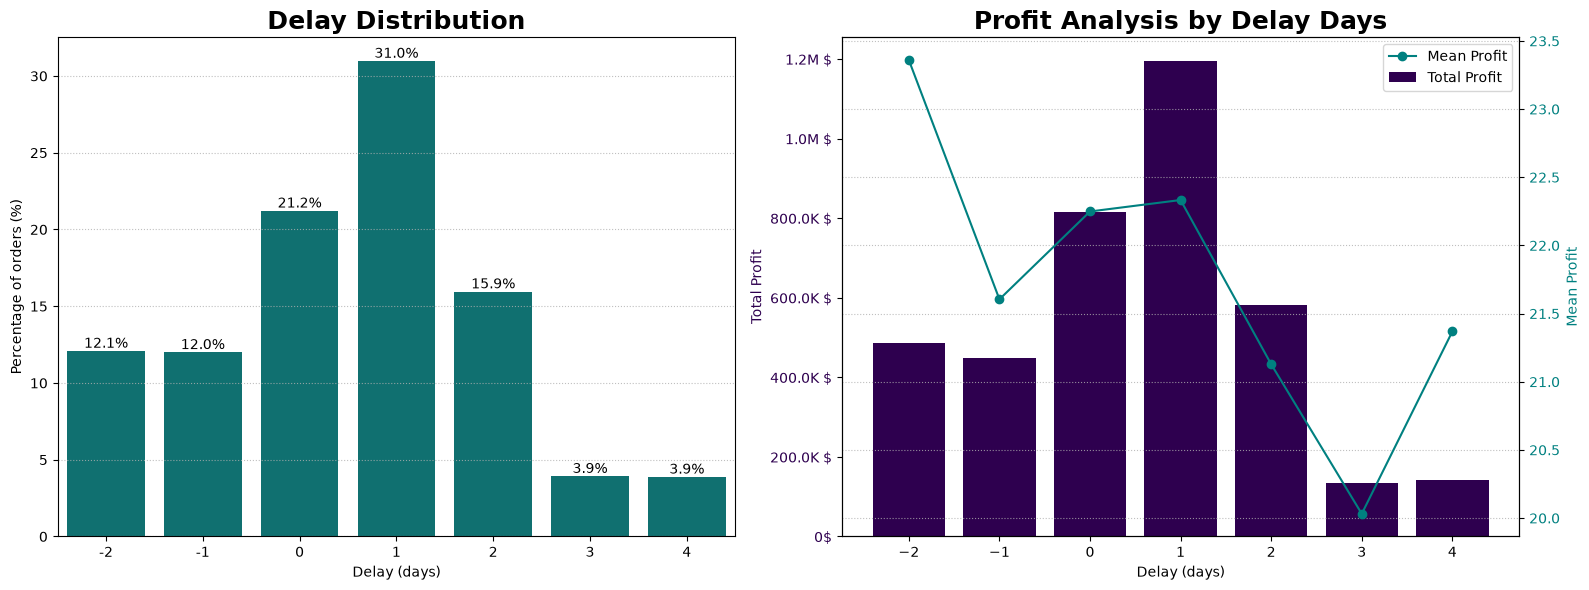

In [24]:
delay_distribution.columns = ["Delay_Days","Percentage"]

print("\nProfit Metrics by Delay Days:")
display(profit_metrics.round(2))

print("\nDelay Distribution (%):")
display(delay_distribution)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))

# First subplot: Delay Ditribution
bars = sns.barplot(x="Delay_Days",y="Percentage", data=delay_distribution, color="teal", ax=ax1)
ax1.set_title("Delay Distribution", fontweight="bold", fontsize=18)
ax1.set_xlabel("Delay (days)")
ax1.set_ylabel("Percentage of orders (%)")
ax1.grid(axis="y", linestyle=":", alpha=0.8)
for container in bars.containers:
    ax1.bar_label(container, fmt="%.1f%%")

# Second subplot: Profit Analysis by Delay Days
ax2.set_ylabel("Total Profit", color = "#2E004F")
ax2.bar(profit_metrics["Delay"], profit_metrics["total_profit"], color = "#2E004F",label="Total Profit")
ax2.tick_params(axis="y",labelcolor="#2E004F")
ax2.set_xlabel("Delay (days)")


ax3=ax2.twinx()
ax3.set_xlabel("Delay Days")
ax3.set_ylabel("Mean Profit", color="teal")
ax3.plot(profit_metrics["Delay"], profit_metrics["mean_profit"], marker="o", label="Mean Profit", color ="teal")
ax3.tick_params(axis="y",labelcolor="teal")

# Format total profit axis to K $ , M$
def format_func(value, tick_number):
    if value >= 1e6:
        return f"{value/1e6:.1f}M $"
    elif value >=1e3:
        return f"{value/1e3:.1f}K $"
    else:
        return f"{value:.0f}$"

ax2.yaxis.set_major_formatter(ticker.FuncFormatter(format_func))

ax3.set_title("Profit Analysis by Delay Days", fontweight="bold", fontsize=18)

lines, labels = ax3.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax3.legend(lines + lines2, labels + labels2, loc = "upper right")
ax3.grid(True, linestyle=":", alpha=0.8)

plt.tight_layout()
plt.show()

## **Bottleneck Detection**

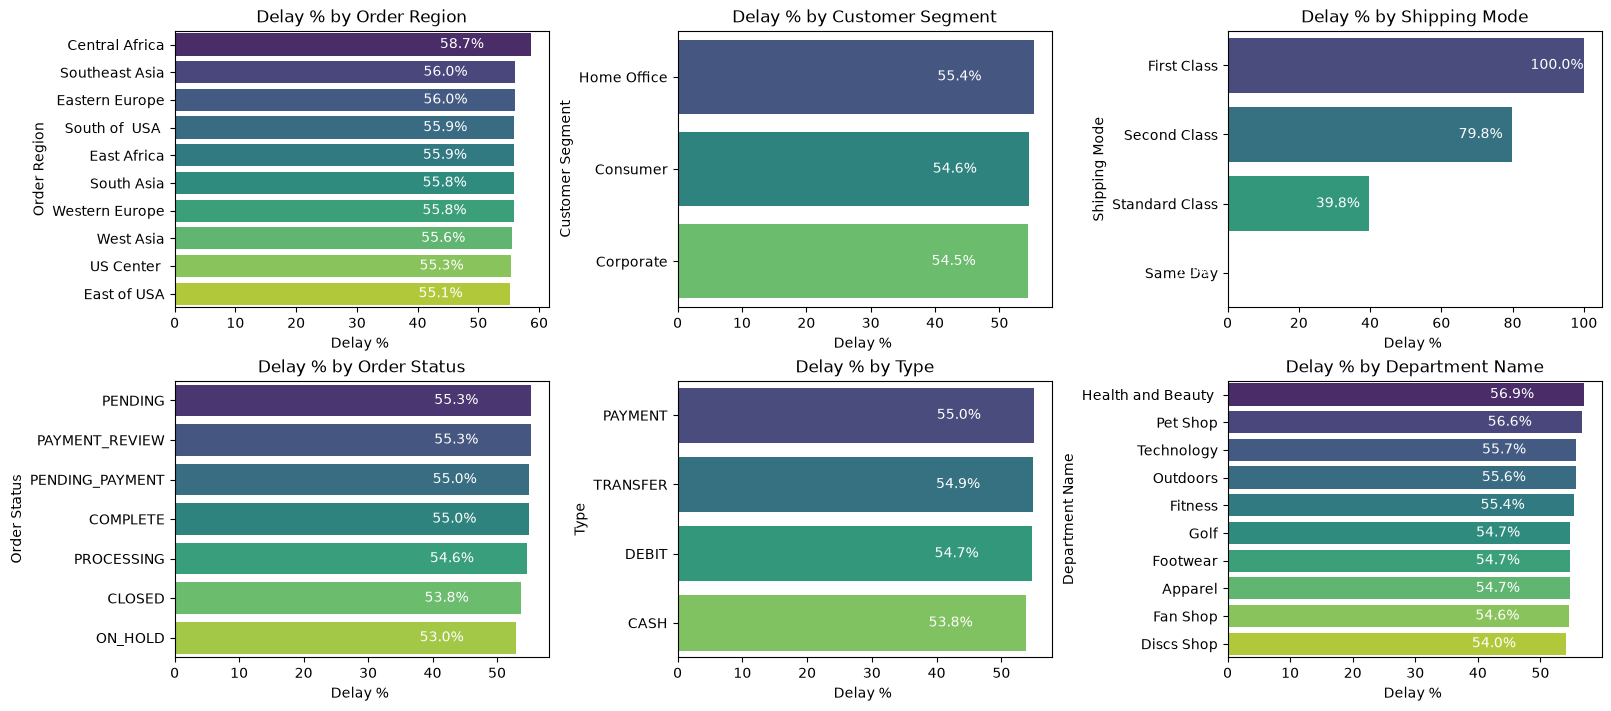

In [25]:
def compute_delay_pct_by_category(category):
    cat_df = df.groupby(category).agg(
        total_orders = ("Delay","count"),
        late_orders = ("Is_Delayed","sum")).reset_index()
    cat_df["delay_pct"] = cat_df["late_orders"] / cat_df["total_orders"] * 100
    cat_df = cat_df.sort_values("delay_pct",ascending=False).head(10)
    return cat_df

categories = ["Order Region", "Customer Segment","Shipping Mode","Order Status","Type","Department Name"]

fig, axes = plt.subplots(2,3,figsize=(16,7),constrained_layout=True)
axes = axes.flatten()

for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_by_category(category)
    sns.barplot(data = cat_df,
               x="delay_pct",
               y=category,
               ax=ax,
               hue=category,
               palette="viridis"
    )
    ax.set_title(f"Delay % by {category}")
    ax.set_xlabel("Delay % ")
    ax.set_ylabel(category)
    for i, row in cat_df.reset_index().iterrows():
        ax.text(row["delay_pct"] - 15, i , f'{row["delay_pct"]:.1f}%',va="center",fontsize=10, color="white")

plt.show()

## **Root Cause Analysis**


Top Drivers of Late Delivery in Central Africa

          Driver                  Factor_Level  delay_pct  avg_delay  total_orders  late_orders
   Shipping Mode    Shipping Mode: First Class     100.00       1.00           278          278
   Shipping Mode   Shipping Mode: Second Class      82.82       2.13           291          241
    Order Status  Order Status: PAYMENT_REVIEW      80.00       1.20            20           16
    Order Status         Order Status: PENDING      69.15       0.57           188          130
            Type                 Type: PAYMENT      63.58       0.76           346          220
            Type                Type: TRANSFER      63.26       0.61           411          260
    Order Status Order Status: PENDING_PAYMENT      62.58       0.74           326          204
 Department Name     Department Name: Outdoors      61.25       0.80            80           49
 Department Name         Department Name: Golf      60.83       0.67           337     

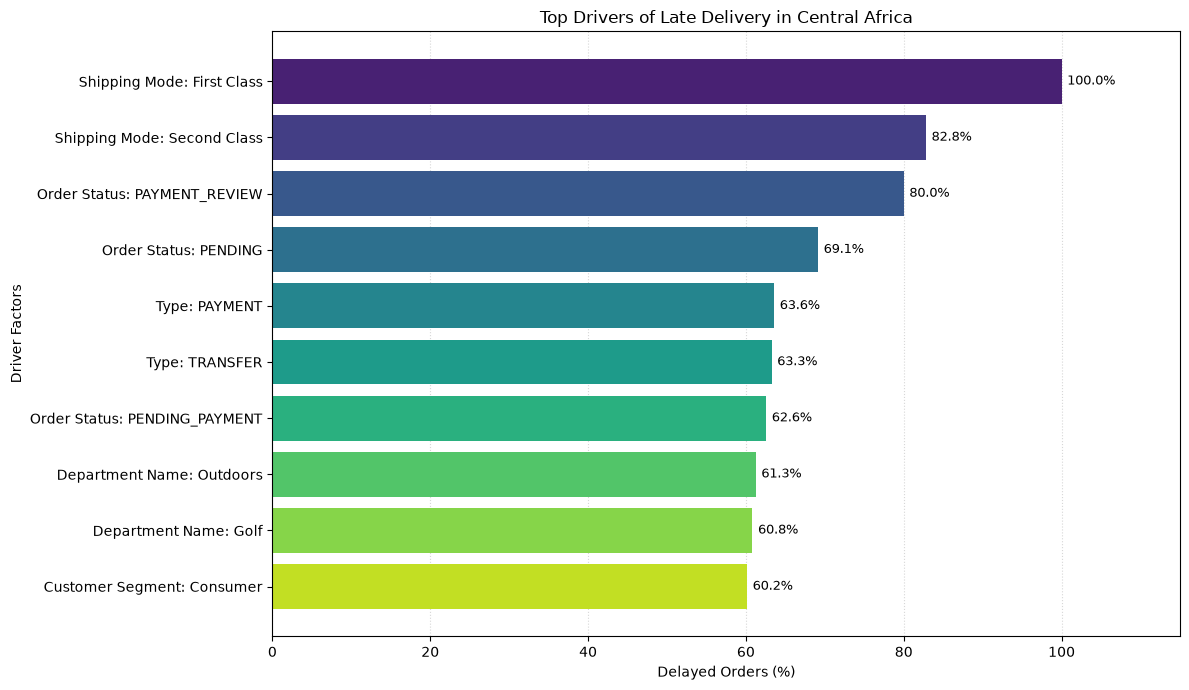

In [26]:
# Top drivers of late delivery by region
def top_drivers_for_region(region):

    df_region = df[df["Order Region"] == region].copy()

    if df_region.empty:
        print(f"No data found for region: {region}")
        return

    drivers = [
        "Shipping Mode",
        "Customer Segment",
        "Department Name",
        "Type",
        "Order Status"
    ]

    all_factors = []

    for factor in drivers:

        temp = (
            df_region.groupby(factor, dropna=False)
            .agg(
                total_orders=("Delay", "count"),
                late_orders=("Is_Delayed", "sum"),
                avg_delay=("Delay", "mean")
            )
            .reset_index()
        )

        # Avoid division by zero
        temp = temp[temp["total_orders"] > 0].copy()

        temp["delay_pct"] = (
            temp["late_orders"] / temp["total_orders"] * 100
        )

        temp["Driver"] = factor

        temp["Factor_Level"] = (
            factor + ": " + temp[factor].fillna("Missing").astype(str)
        )

        all_factors.append(
            temp[
                [
                    "Driver",
                    "Factor_Level",
                    "delay_pct",
                    "avg_delay",
                    "total_orders",
                    "late_orders"
                ]
            ]
        )

    # Combine all driver factors
    final_df = pd.concat(all_factors, ignore_index=True)

    # Select top 10 factor levels by delay percentage
    top_factors = (
        final_df.sort_values("delay_pct", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )

    # Print the results
    print(f"\nTop Drivers of Late Delivery in {region}\n")

    print(
        top_factors[
            [
                "Driver",
                "Factor_Level",
                "delay_pct",
                "avg_delay",
                "total_orders",
                "late_orders"
            ]
        ].round(2).to_string(index=False)
    )

    # Plot horizontal bar chart
    fig, ax = plt.subplots(figsize=(12, 7))

    colors = sns.color_palette("viridis", n_colors=len(top_factors))

    bars = ax.barh(
        top_factors["Factor_Level"],
        top_factors["delay_pct"],
        color=colors
    )

    ax.set_xlabel("Delayed Orders (%)")
    ax.set_ylabel("Driver Factors")
    ax.set_title(f"Top Drivers of Late Delivery in {region}")

    ax.grid(axis="x", linestyle=":", alpha=0.5)
    ax.set_axisbelow(True)

    # Put the highest percentage at the top
    ax.invert_yaxis()

    # Add percentage labels
    ax.bar_label(
        bars,
        labels=[f"{value:.1f}%" for value in top_factors["delay_pct"]],
        padding=4,
        fontsize=9
    )

    # Leave space for percentage labels
    max_pct = top_factors["delay_pct"].max()

    if pd.notna(max_pct):
        ax.set_xlim(0, max_pct * 1.15 if max_pct > 0 else 1)


    plt.tight_layout()
    plt.show()

    return top_factors

top_factors = top_drivers_for_region("Central Africa")

## **Time-Based Analysis**

In [27]:
# Delay % by Month, Day of Week, Hour

delay_by_month = (
    df.groupby("order_month")["Is_Delayed"]
    .mean()
    .reset_index())

delay_by_month["delay_pct"] = delay_by_month["Is_Delayed"] * 100

delay_by_day = (
    df.groupby("order_day")["Is_Delayed"]
    .mean()
    .reset_index())

delay_by_day["delay_pct"] = delay_by_day["Is_Delayed"] * 100

delay_by_hour = (
    df.groupby("order_hour")["Is_Delayed"]
    .mean()
    .reset_index())

delay_by_hour["delay_pct"] = delay_by_hour["Is_Delayed"] * 100

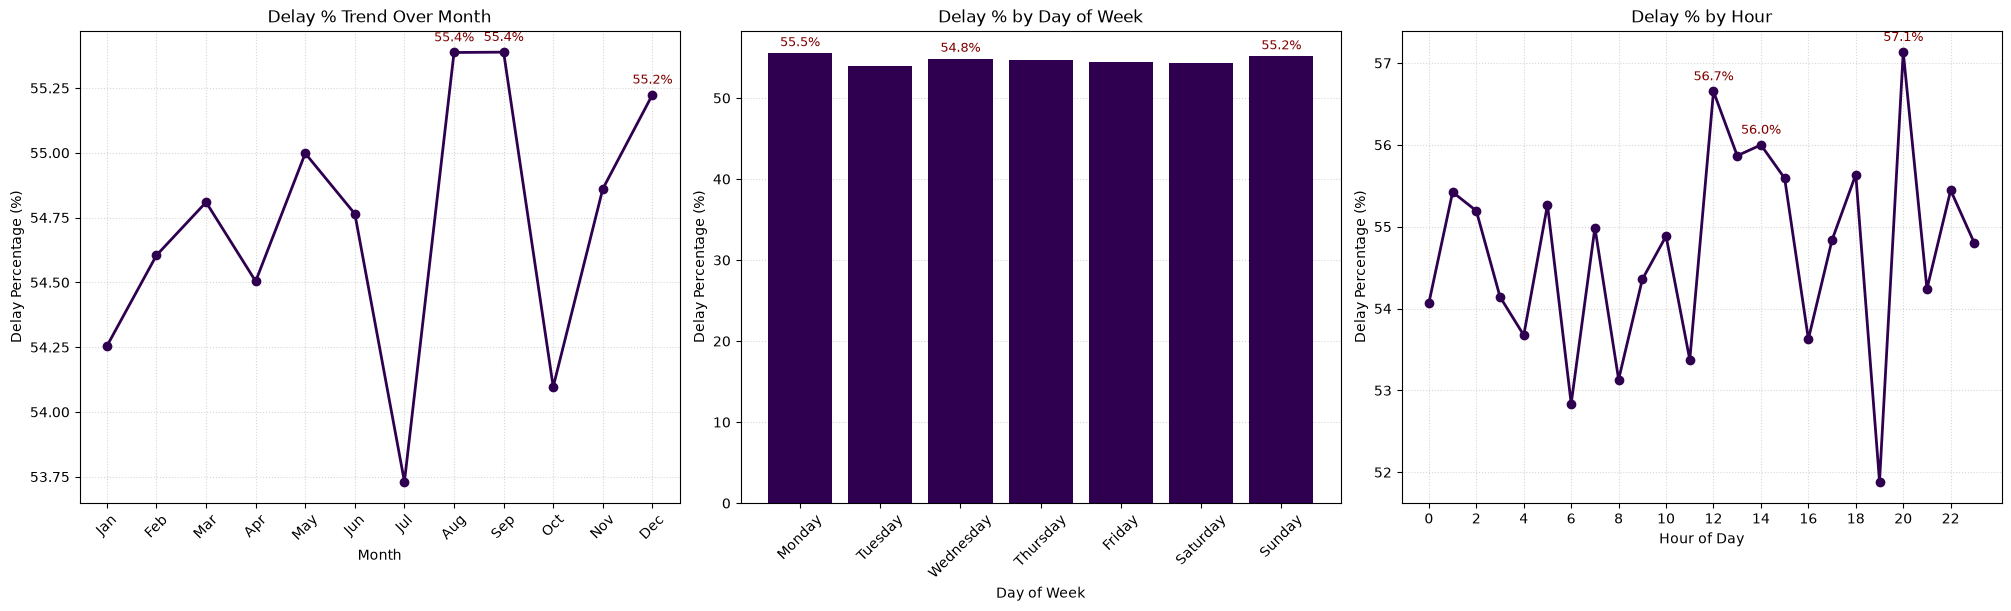

In [29]:
fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3, figsize=(20, 6), constrained_layout=True
)


# Subplot 1: Delay % Trend Over Month
delay_by_month = delay_by_month.sort_values("order_month")

ax1.plot(
    delay_by_month["order_month"],
    delay_by_month["delay_pct"],
    color="#2E004F",
    marker="o",
    linewidth=2
)

ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=45
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month")
ax1.grid(True, linestyle=":", alpha=0.5)

# Annotate top 3 highest months
top3_month = delay_by_month.nlargest(3, "delay_pct")

for _, row in top3_month.iterrows():
    ax1.annotate(
        f'{row["delay_pct"]:.1f}%',
        (row["order_month"], row["delay_pct"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        color="maroon"
    )


# Subplot 2: Delay % by Day of Week
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

delay_by_day["order_day"] = pd.Categorical(
    delay_by_day["order_day"],
    categories=day_order,
    ordered=True
)

delay_by_day = delay_by_day.sort_values("order_day")

bars2 = ax2.bar(
    delay_by_day["order_day"].astype(str),
    delay_by_day["delay_pct"],
    color="#2E004F"
)

ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay Percentage (%)")
ax2.set_title("Delay % by Day of Week")
ax2.tick_params(axis="x", rotation=45)
ax2.grid(axis="y", linestyle=":", alpha=0.5)
ax2.set_axisbelow(True)

# Annotate top 3 highest days
top3_day = delay_by_day.nlargest(3, "delay_pct")

for _, row in top3_day.iterrows():
    day_name = str(row["order_day"])
    x_pos = day_order.index(day_name)

    ax2.annotate(
        f'{row["delay_pct"]:.1f}%',
        (x_pos, row["delay_pct"]),
        textcoords="offset points",
        xytext=(0, 5),
        ha="center",
        fontsize=9,
        color="maroon"
    )


# Subplot 3: Delay % by Hour
delay_by_hour = delay_by_hour.sort_values("order_hour")

ax3.plot(
    delay_by_hour["order_hour"],
    delay_by_hour["delay_pct"],
    color="#2E004F",
    marker="o",
    linewidth=2
)

ax3.set_xticks(range(0, 24, 2))
ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour")
ax3.grid(True, linestyle=":", alpha=0.5)

# Annotate top 3 highest hours
top3_hour = delay_by_hour.nlargest(3, "delay_pct")

for _, row in top3_hour.iterrows():
    ax3.annotate(
        f'{row["delay_pct"]:.1f}%',
        (row["order_hour"], row["delay_pct"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        color="maroon"
    )

plt.show()

## **Machine Learning Model**

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

In [31]:
X = df[["Type","Days for shipment (scheduled)","Category Name","Customer Segment","Department Name","Order Region","Shipping Mode","order_month","order_hour"]]
y = df["Late_delivery_risk"]

In [32]:
cat_cols = X.select_dtypes(include=["object","category","str"]).columns.to_list()
print("Categorical Columns:", cat_cols)

# Frequency Encoding (low_dimensional and robust for high-cardinality)
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X[f"{col}_freq"] = X[col].map(freq)

# Keep numeric columns + new encoded features, drop original string categories
X_encoded = X.drop(columns=(cat_cols))
print("Shape after freq + target encoding", X_encoded.shape)

# Use encoded features for modeling
X = X_encoded

# Train/Test split after encoding
X_train , X_test, y_train, y_test = train_test_split(X, y , test_size=0.2, random_state=42, stratify=y)

Categorical Columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']
Shape after freq + target encoding (172765, 9)


In [33]:
y.value_counts()

Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

In [36]:
# Balancing the training data using SMOTE
print("Before balancing (train):", Counter(y_train))

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("After balancing (train):", Counter(y_train_bal))

Before balancing (train): Counter({1: 79182, 0: 59030})
After balancing (train): Counter({0: 79182, 1: 79182})


In [37]:
def evaluate_model(y_true,y_pred,model_name):
    print(f"---{model_name}---")
    print("Accuracy:", round(accuracy_score(y_true,y_pred),2))
    print("Precision:", round(precision_score(y_true,y_pred),2))
    print("Recall:", round(recall_score(y_true,y_pred),2))
    print("\nClassification Report:\n", classification_report(y_true,y_pred))

In [38]:
# Fitting Random Forest model on balanced data
rf_model_balanced = RandomForestClassifier(random_state=42)
rf_model_balanced.fit(X_train_bal, y_train_bal)

y_pred_rf_balanced = rf_model_balanced.predict(X_test)

evaluate_model(y_test, y_pred_rf_balanced, "Random Forest Classifier")

---Random Forest Classifier---
Accuracy: 0.74
Precision: 0.79
Recall: 0.75

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.73      0.70     14758
           1       0.79      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553

